In [ ]:
# Copyright (c) Meta Platforms, Inc. and affiliates.

# Object masks in images from prompts with SAM 2

Segment Anything Model 2 (SAM 2) predicts object masks given prompts that indicate the desired object. The model first converts the image into an image embedding that allows high quality masks to be efficiently produced from a prompt.

The `SAM2ImagePredictor` class provides an easy interface to the model for prompting the model. It allows the user to first set an image using the `set_image` method, which calculates the necessary image embeddings. Then, prompts can be provided via the `predict` method to efficiently predict masks from those prompts. The model can take as input both point and box prompts, as well as masks from the previous iteration of prediction.

<a target="_blank" href="https://colab.research.google.com/github/facebookresearch/sam2/blob/main/notebooks/image_predictor_example.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## Environment Set-up

If running locally using jupyter, first install `sam2` in your environment using the [installation instructions](https://github.com/facebookresearch/sam2#installation) in the repository.

If running from Google Colab, set `using_colab=True` below and run the cell. In Colab, be sure to select 'GPU' under 'Edit'->'Notebook Settings'->'Hardware accelerator'. Note that it's recommended to use **A100 or L4 GPUs when running in Colab** (T4 GPUs might also work, but could be slow and might run out of memory in some cases).

In [5]:
using_colab = True

In [6]:
if using_colab:
    import torch
    import torchvision
    print("PyTorch version:", torch.__version__)
    print("Torchvision version:", torchvision.__version__)
    print("CUDA is available:", torch.cuda.is_available())
    import sys
    !{sys.executable} -m pip install opencv-python matplotlib
    !{sys.executable} -m pip install 'git+https://github.com/facebookresearch/sam2.git'

    !mkdir -p images
    !wget -P images https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/truck.jpg
    !wget -P images https://raw.githubusercontent.com/facebookresearch/sam2/main/notebooks/images/groceries.jpg


    !mkdir -p ../checkpoints/
    !wget -P ../checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt

PyTorch version: 2.11.0+cu130
Torchvision version: 0.26.0+cu130
CUDA is available: True
  Cloning https://github.com/facebookresearch/sam2.git to /tmp/pip-req-build-xnhzdylj
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/sam2.git /tmp/pip-req-build-xnhzdylj
  Resolved https://github.com/facebookresearch/sam2.git to commit 2b90b9f5ceec907a1c18123530e92e794ad901a4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 4.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 14.7 MB/s eta 0:00:00
  Created wheel for SAM-2: filename=sam_2-1.0-cp313-cp313-linux_x86_64.whl size=535022 sha256=e33ccc50b4778c230b64c0fbc5694f1f63e795ea76a1eb654415331ba78e4825
  Stored in di

In [7]:
# Source - https://stackoverflow.com/a/50808076
# Posted by DataFramed, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-07, License - CC BY-SA 4.0

from google.colab import files
from io import BytesIO
from PIL import Image

uploaded = files.upload()
#im = Image.open(BytesIO(uploaded[]))


Saving example.png to example.png


In [8]:
im = Image.open(BytesIO(uploaded['example.png']))

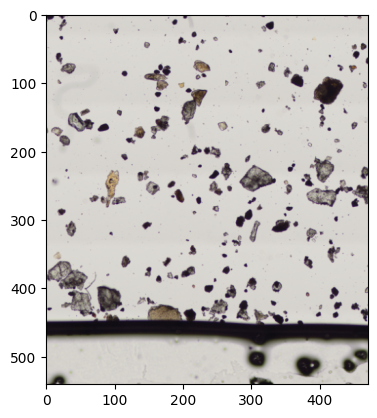

In [11]:
# Source - https://stackoverflow.com/a/50808076
# Posted by DataFramed, modified by community. See post 'Timeline' for change history
# Retrieved 2026-10-07, License - CC BY-SA 4.0

import matplotlib.pyplot as plt
import numpy as np

plt.imshow(im)
plt.show()

im = np.array(im.convert("RGB"))

## Set-up

Necessary imports and helper functions for displaying points, boxes, and masks.

In [12]:
import os
# if using Apple MPS, fall back to CPU for unsupported ops
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

In [13]:
# select the device for computation
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"using device: {device}")

if device.type == "cuda":
    # use bfloat16 for the entire notebook
    torch.autocast("cuda", dtype=torch.bfloat16).__enter__()
    # turn on tfloat32 for Ampere GPUs (https://pytorch.org/docs/stable/notes/cuda.html#tensorfloat-32-tf32-on-ampere-devices)
    if torch.cuda.get_device_properties(0).major >= 8:
        torch.backends.cuda.matmul.allow_tf32 = True
        torch.backends.cudnn.allow_tf32 = True
elif device.type == "mps":
    print(
        "\nSupport for MPS devices is preliminary. SAM 2 is trained with CUDA and might "
        "give numerically different outputs and sometimes degraded performance on MPS. "
        "See e.g. https://github.com/pytorch/pytorch/issues/84936 for a discussion."
    )

using device: cuda


In [14]:
np.random.seed(3)

def show_mask(mask, ax, random_color=False, borders = True):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    mask = mask.astype(np.uint8)
    mask_image =  mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    if borders:
        import cv2
        contours, _ = cv2.findContours(mask,cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        # Try to smooth contours
        contours = [cv2.approxPolyDP(contour, epsilon=0.01, closed=True) for contour in contours]
        mask_image = cv2.drawContours(mask_image, contours, -1, (1, 1, 1, 0.5), thickness=2)
    ax.imshow(mask_image)

def show_points(coords, labels, ax, marker_size=375):
    pos_points = coords[labels==1]
    neg_points = coords[labels==0]
    ax.scatter(pos_points[:, 0], pos_points[:, 1], color='green', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)
    ax.scatter(neg_points[:, 0], neg_points[:, 1], color='red', marker='*', s=marker_size, edgecolor='white', linewidth=1.25)

def show_box(box, ax):
    x0, y0 = box[0], box[1]
    w, h = box[2] - box[0], box[3] - box[1]
    ax.add_patch(plt.Rectangle((x0, y0), w, h, edgecolor='green', facecolor=(0, 0, 0, 0), lw=2))

def show_masks(image, masks, scores, point_coords=None, box_coords=None, input_labels=None, borders=True):
    for i, (mask, score) in enumerate(zip(masks, scores)):
        plt.figure(figsize=(10, 10))
        plt.imshow(image)
        show_mask(mask, plt.gca(), borders=borders)
        if point_coords is not None:
            assert input_labels is not None
            show_points(point_coords, input_labels, plt.gca())
        if box_coords is not None:
            # boxes
            show_box(box_coords, plt.gca())
        if len(scores) > 1:
            plt.title(f"Mask {i+1}, Score: {score:.3f}", fontsize=18)
        plt.axis('off')
        plt.show()

## Example image

In [15]:
image = Image.open('images/truck.jpg')
image = np.array(image.convert("RGB"))

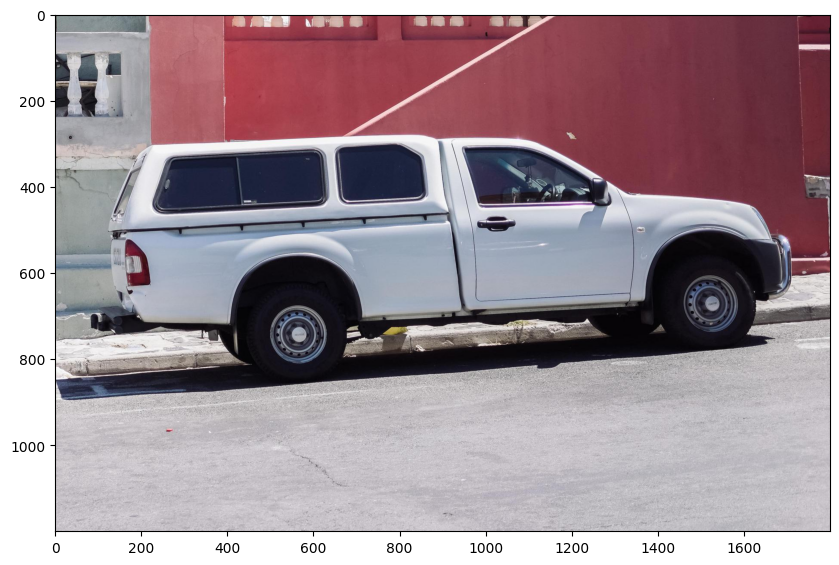

In [16]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis('on')
plt.show()

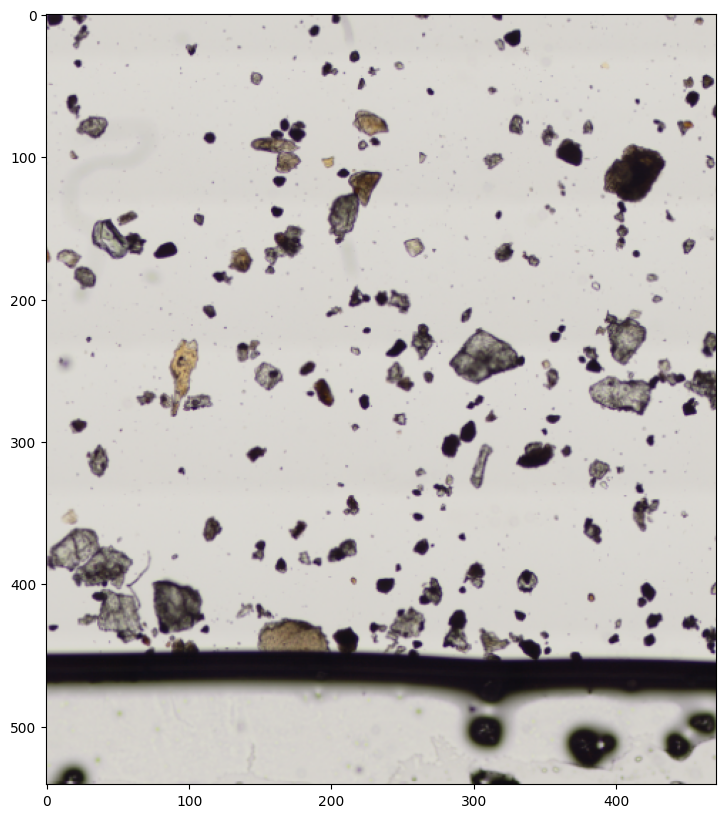

In [17]:
plt.figure(figsize=(10, 10))
plt.imshow(im)
plt.axis('on')
plt.show()

## Selecting objects with SAM 2

First, load the SAM 2 model and predictor. Change the path below to point to the SAM 2 checkpoint. Running on CUDA and using the default model are recommended for best results.

In [18]:
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

sam2_checkpoint = "../checkpoints/sam2.1_hiera_large.pt"
model_cfg = "configs/sam2.1/sam2.1_hiera_l.yaml"

sam2_model = build_sam2(model_cfg, sam2_checkpoint, device=device)

predictor = SAM2ImagePredictor(sam2_model)

Process the image to produce an image embedding by calling `SAM2ImagePredictor.set_image`. `SAM2ImagePredictor` remembers this embedding and will use it for subsequent mask prediction.

In [19]:
predictor.set_image(image)

To select the truck, choose a point on it. Points are input to the model in (x,y) format and come with labels 1 (foreground point) or 0 (background point). Multiple points can be input; here we use only one. The chosen point will be shown as a star on the image.

In [20]:
input_point = np.array([[500, 375]])
input_label = np.array([1])

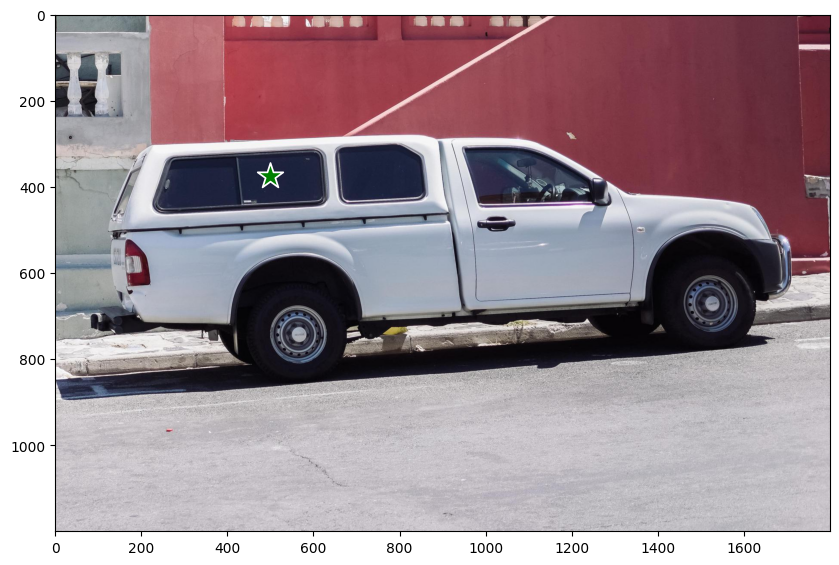

In [21]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
show_points(input_point, input_label, plt.gca())
plt.axis('on')
plt.show()

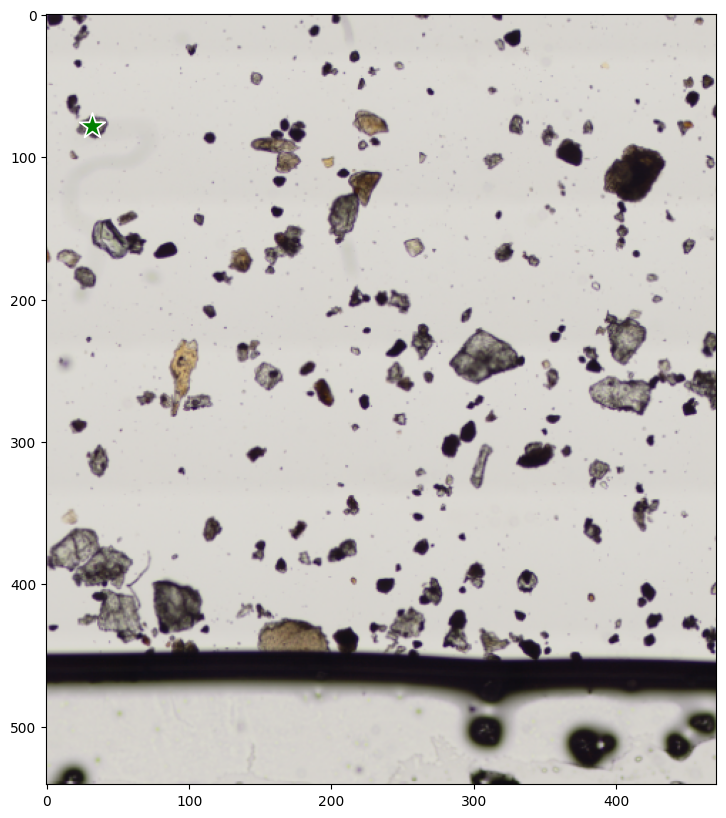

In [22]:
predictor.set_image(im)
input_point = np.array([[32, 78]])
input_label = np.array([1])
plt.figure(figsize=(10, 10))
plt.imshow(im)
show_points(input_point, input_label, plt.gca())
plt.axis('on')
plt.show()

In [23]:
print(predictor._features["image_embed"].shape, predictor._features["image_embed"][-1].shape)

torch.Size([1, 256, 64, 64]) torch.Size([256, 64, 64])


Predict with `SAM2ImagePredictor.predict`. The model returns masks, quality predictions for those masks, and low resolution mask logits that can be passed to the next iteration of prediction.

In [24]:
masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True,
)
sorted_ind = np.argsort(scores)[::-1]
masks = masks[sorted_ind]
scores = scores[sorted_ind]
logits = logits[sorted_ind]

With `multimask_output=True` (the default setting), SAM 2 outputs 3 masks, where `scores` gives the model's own estimation of the quality of these masks. This setting is intended for ambiguous input prompts, and helps the model disambiguate different objects consistent with the prompt. When `False`, it will return a single mask. For ambiguous prompts such as a single point, it is recommended to use `multimask_output=True` even if only a single mask is desired; the best single mask can be chosen by picking the one with the highest score returned in `scores`. This will often result in a better mask.

In [25]:
masks.shape  # (number_of_masks) x H x W

(3, 541, 471)

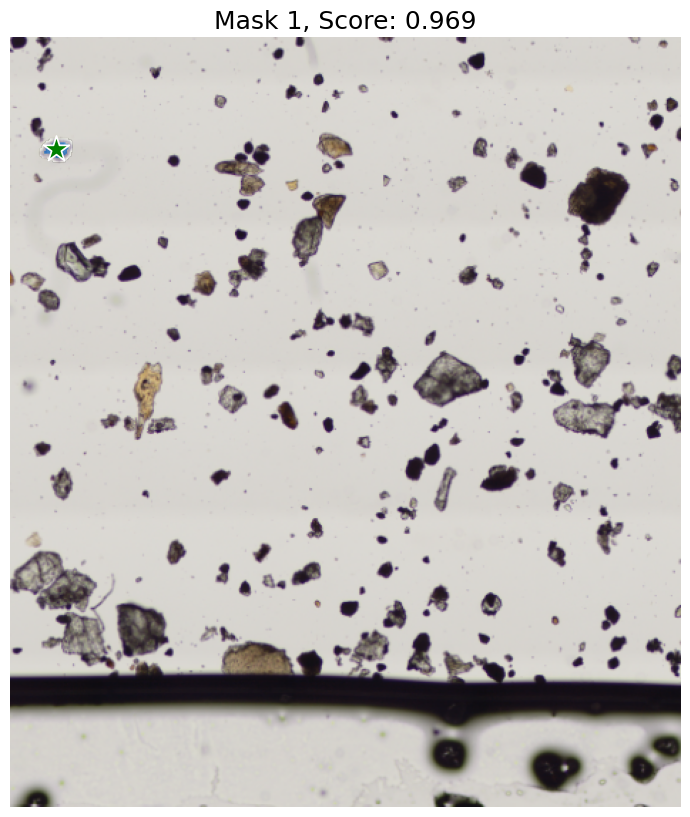

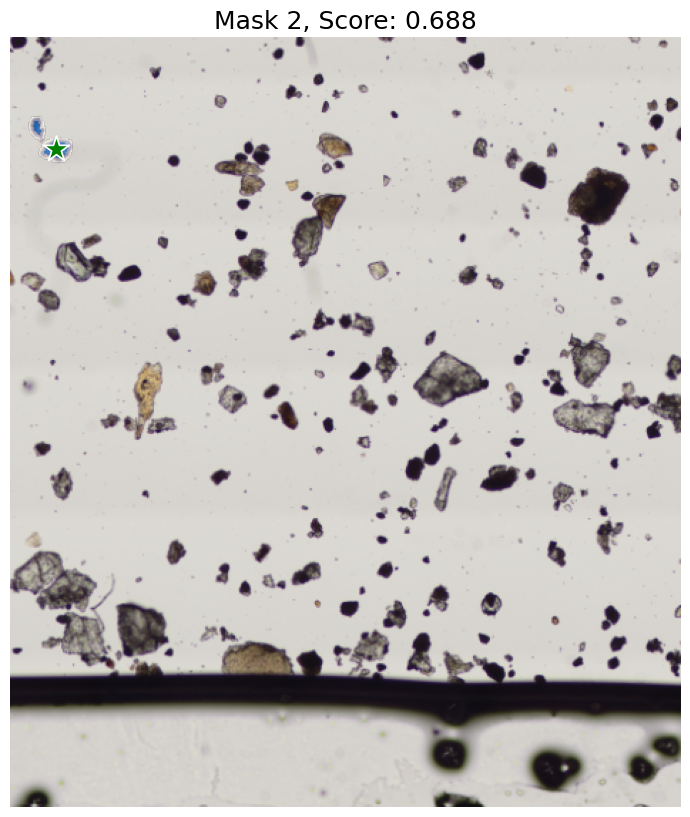

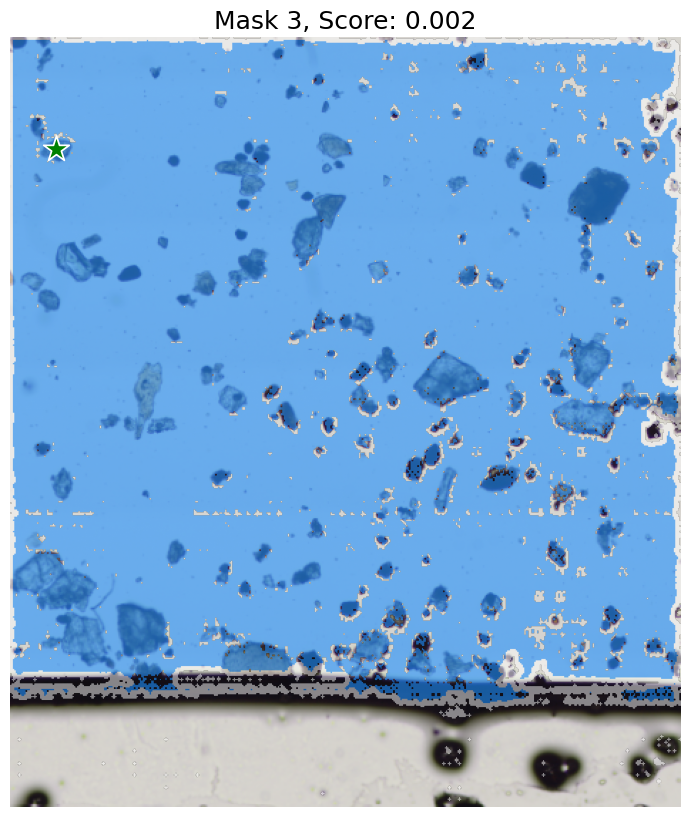

In [26]:
show_masks(im, masks, scores, point_coords=input_point, input_labels=input_label, borders=True)

## Specifying a specific object with additional points

The single input point is ambiguous, and the model has returned multiple objects consistent with it. To obtain a single object, multiple points can be provided. If available, a mask from a previous iteration can also be supplied to the model to aid in prediction. When specifying a single object with multiple prompts, a single mask can be requested by setting `multimask_output=False`.

In [31]:
# input_point = np.array([[32, 78], [141, 78]])
# input_label = np.array([1, 1])

# mask_input = logits[np.argmax(scores), :, :]  # Choose the model's best mask

input_point = np.array([[32, 78], [141, 78]])
input_label = np.array([1, 1])

# Select the first mask (Mask 1) from the previous predictions
mask_input = logits[0, :, :]

In [27]:
input_point = np.array([[32, 78], [141, 78]])
input_label = np.array([1, 1])

# Select the first mask (Mask 1) from the previous predictions
mask_input = logits[0, :, :]

In [32]:
masks, scores, _ = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    mask_input=mask_input[None, :, :],
    multimask_output=False,
)

In [33]:
masks.shape

(1, 541, 471)

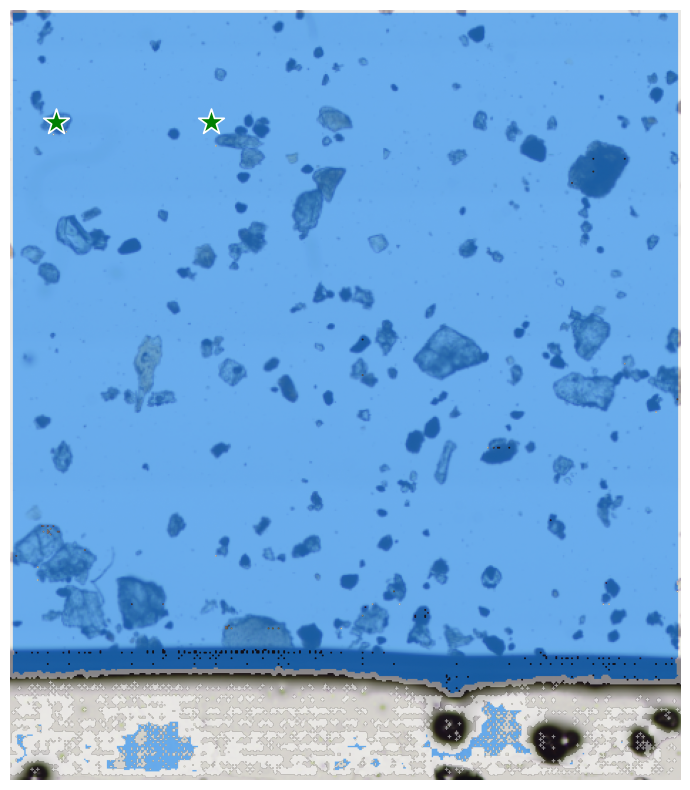

In [34]:
show_masks(im, masks, scores, point_coords=input_point, input_labels=input_label)

To exclude the car and specify just the window, a background point (with label 0, here shown in red) can be supplied.

In [42]:
input_point = np.array([[32, 78], [100, 78]])
input_label = np.array([1, 0])

#mask_input = logits[np.argmax(scores), :, :]  # Choose the model's best mask
mask_input = logits[0, :, :]

In [43]:
masks, scores, _ = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    mask_input=mask_input[None, :, :],
    multimask_output=False,
)

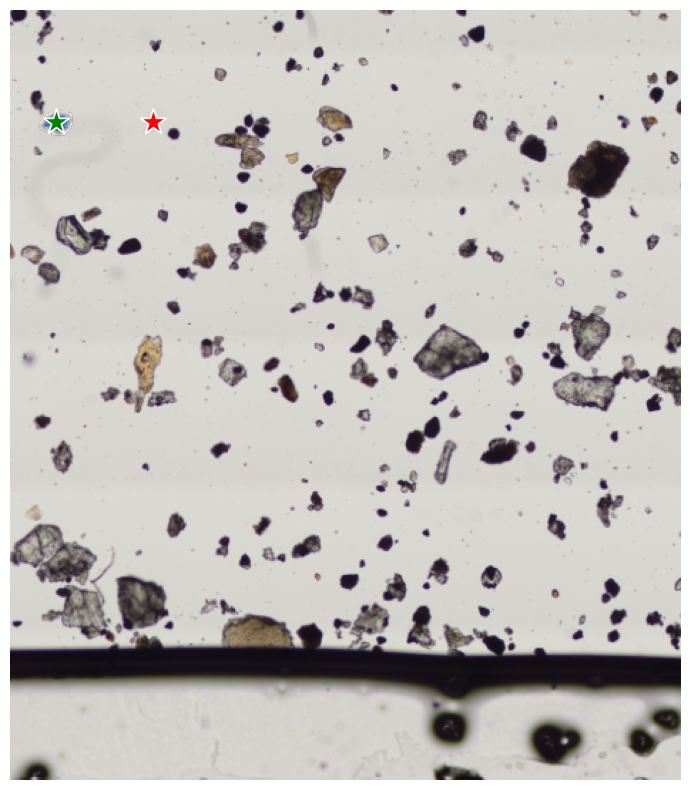

In [44]:
show_masks(im, masks, scores, point_coords=input_point, input_labels=input_label)

## Specifying a specific object with a box

The model can also take a box as input, provided in xyxy format.

In [90]:
input_box = np.array([20, 70, 50, 90])

In [91]:
masks, scores, _ = predictor.predict(
    point_coords=None,
    point_labels=None,
    box=input_box[None, :],
    multimask_output=False,
)

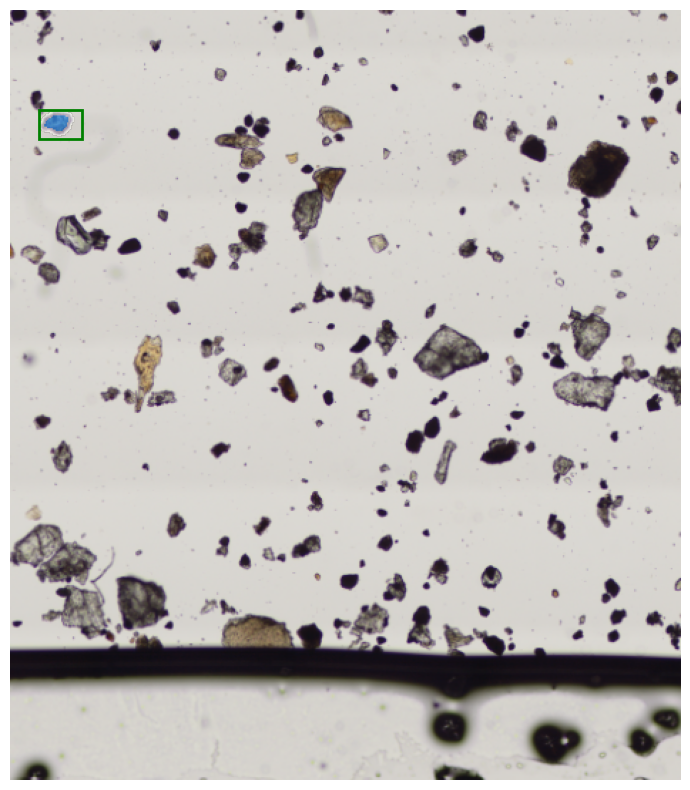

In [92]:
show_masks(im, masks, scores, box_coords=input_box)

Detected 123 particles.


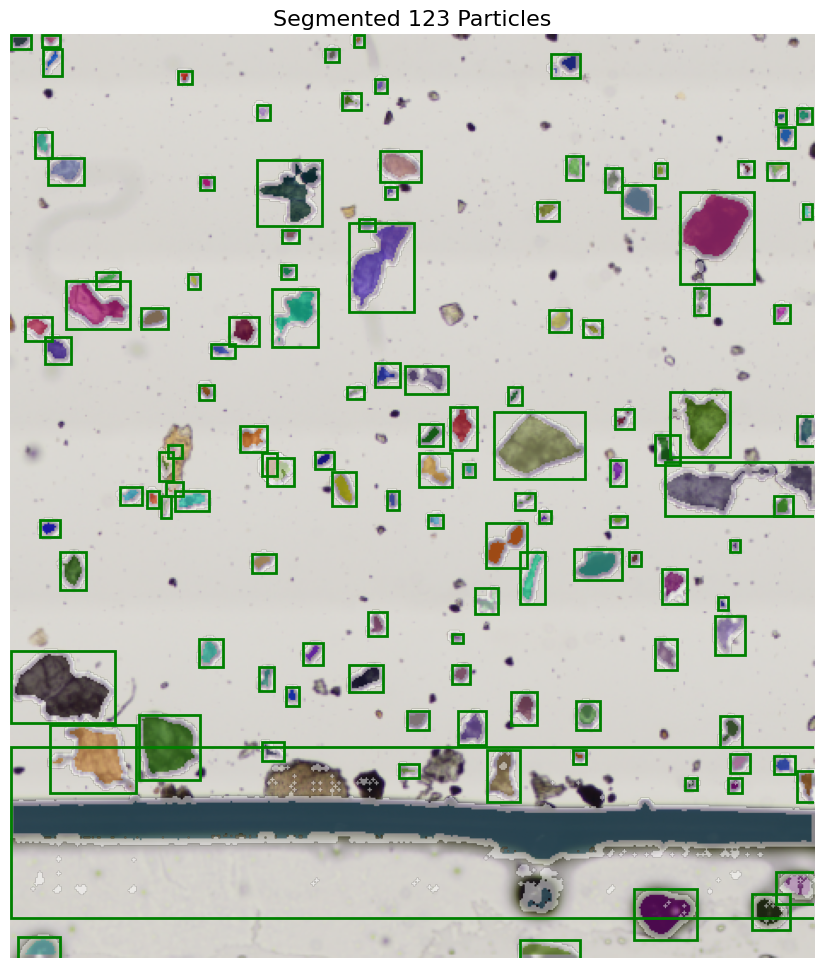

In [93]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Convert image to grayscale and apply thresholding to find particles
gray = cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)
# Using Otsu's thresholding (assuming dark particles on a light background)
_, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# 2. Find contours of the particles
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# 3. Filter contours by size to ignore noise/extremely small artifacts
min_area = 20  # Adjust as needed depending on particle size
input_boxes = []
for cnt in contours:
    if cv2.contourArea(cnt) > min_area:
        x, y, w, h = cv2.boundingRect(cnt)
        # SAM 2 expects boxes in [x1, y1, x2, y2] format
        input_boxes.append([x, y, x + w, y + h])

input_boxes = np.array(input_boxes)
print(f"Detected {len(input_boxes)} particles.")

# 4. Predict masks for all detected boxes using SAM 2 batched prediction
if len(input_boxes) > 0:
    # Set image in the predictor
    predictor.set_image(im)

    # Predict masks for all boxes in batch
    masks, scores, _ = predictor.predict(
        point_coords=None,
        point_labels=None,
        box=input_boxes,
        multimask_output=False,
    )

    # 5. Visualize the final masks and bounding boxes on the image
    plt.figure(figsize=(12, 12))
    plt.imshow(im)

    # Plot each predicted mask with a random color
    for mask in masks:
        show_mask(mask.squeeze(0), plt.gca(), random_color=True, borders=True)

    # Plot each bounding box
    for box in input_boxes:
        show_box(box, plt.gca())

    plt.title(f"Segmented {len(input_boxes)} Particles", fontsize=16)
    plt.axis('off')
    plt.show()
else:
    print("No particles detected. Please adjust the threshold or minimum area.")

### 1. Install Grounding DINO
We will clone and install the official Grounding DINO repository.

In [1]:
%cd /content

!git clone https://github.com/IDEA-Research/Grounded-SAM-2.git
%cd Grounded-SAM-2

/content
Cloning into 'Grounded-SAM-2'...
remote: Enumerating objects: 2065, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 2065 (delta 11), reused 5 (delta 5), pack-reused 2046 (from 2)
Receiving objects: 100% (2065/2065), 230.08 MiB | 36.69 MiB/s, done.
Resolving deltas: 100% (769/769), done.
/content/Grounded-SAM-2


In [2]:
!pip install -q torch torchvision

!pip install -q supervision
!pip install -q opencv-python
!pip install -q pycocotools
!pip install -q matplotlib
!pip install -q transformers
!pip install -q accelerate
!pip install -q addict
!pip install -q yapf

!pip install -e .


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 21.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 10.4 MB/s eta 0:00:00
Obtaining file:///content/Grounded-SAM-2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 168.8/168.8 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 15.4 MB

In [3]:
%cd /content

!git clone https://github.com/facebookresearch/sam2.git

%cd sam2

!pip install -e .

%cd /content/Grounded-SAM-2

/content
Cloning into 'sam2'...
remote: Enumerating objects: 1107, done.
remote: Counting objects: 100% (18/18), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 1107 (delta 13), reused 7 (delta 7), pack-reused 1089 (from 2)
Receiving objects: 100% (1107/1107), 134.85 MiB | 31.73 MiB/s, done.
Resolving deltas: 100% (385/385), done.
/content/sam2
Obtaining file:///content/sam2
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for SAM-2 (pyproject.toml) ... done
  Created wheel for SAM-2: filename=sam_2-1.0-0.editable-cp313-cp313-linux_x86_64.whl size=13851 sha256=a7abeca7518eb41938bb253113e7815dfeea205f73f120f48311e641fd282672
  Stored in directory: /tmp/pip-ephem-wheel-cache-izye6zej/wheels/64/e2/28/d1780fb444d6d91bdaddca8d1cc2203826a9783d0f6c5c6e84
Successfully built SAM-2
  Attempting unin

In [4]:
!mkdir -p gdino_checkpoints

!wget -P gdino_checkpoints \
https://github.com/IDEA-Research/GroundingDINO/releases/download/v0.1.0-alpha/groundingdino_swint_ogc.pth

--2026-10-09 08:32:12--  https://github.com/IDEA-Research/GroundingDINO/releases/download/v0.1.0-alpha/groundingdino_swint_ogc.pth
Resolving github.com (github.com)... 140.82.116.3
Connecting to github.com (github.com)|140.82.116.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/611591640/f221e500-c2fc-4fd3-b84e-8ad92a6923f3?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-09T09%3A17%3A22Z&rscd=attachment%3B+filename%3Dgroundingdino_swint_ogc.pth&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-09T08%3A17%3A18Z&ske=2026-10-09T09%3A17%3A22Z&sks=b&skv=2018-11-09&sig=n%2BQvvpj2AREAtCK%2FsXiI0EeuKEFeIjzZRrIv2C72wO8%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MTUzODMzMiwibmJmIjoxNzkxNTM0NzMyLCJw

In [5]:
!mkdir -p checkpoints

!wget -P checkpoints \
https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt

--2026-10-09 08:32:43--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_large.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 99.86.101.115, 99.86.101.47, 99.86.101.24, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|99.86.101.115|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 898083611 (856M) [application/vnd.snesdev-page-table]
Saving to: ‘checkpoints/sam2.1_hiera_large.pt’

sam2.1_hiera_large. 100%[===================>] 856.48M   220MB/s    in 3.8s    

2026-10-09 08:32:47 (223 MB/s) - ‘checkpoints/sam2.1_hiera_large.pt’ saved [898083611/898083611]



(np.float64(-0.5), np.float64(470.5), np.float64(540.5), np.float64(-0.5))

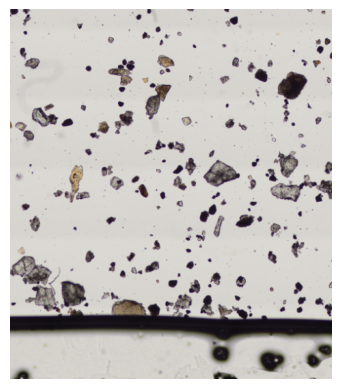

In [9]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = "/content/test.jpg"

#img = Image.open(image_path)
plt.imshow(im)
plt.axis("off")

### 2. Download Grounding DINO Weights and Initialize the Model
We download the configuration and pre-trained weights for Grounding DINO.

In [ ]:
import torch
import sys
sys.path.append("./GroundingDINO")

from groundingdino.util.inference import load_model, load_image, predict, annotate
import groundingdino.datasets.transforms as T

# Initialize Grounding DINO model
gd_config_path = "GroundingDINO/groundingdino/config/GroundingDINO_SwinT_OGC.py"
gd_checkpoint_path = "gd_checkpoints/groundingdino_swint_ogc.pth"
gd_model = load_model(gd_config_path, gd_checkpoint_path, device=str(device))

### 3. Detect and Segment Particles using Grounding DINO + SAM 2
We will pass the image to Grounding DINO with the prompt `"particle"` to get bounding boxes, then prompt SAM 2 with these boxes.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Grounding DINO preprocessing pipeline
def preprocess_image_for_gd(image_np):
    transform = T.Compose([
        T.RandomResize([800], max_size=1333),
        T.ToTensor(),
        T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])
    image_pil = Image.fromarray(image_np)
    image_transformed, _ = transform(image_pil, None)
    return image_transformed

# 1. Transform the uploaded image 'im'
image_transformed = preprocess_image_for_gd(im)

# 2. Run Grounding DINO detection
TEXT_PROMPT = "particle"
BOX_TRESHOLD = 0.25
TEXT_TRESHOLD = 0.25

boxes, logits, phrases = predict(
    model=gd_model,
    image=image_transformed,
    caption=TEXT_PROMPT,
    box_threshold=BOX_TRESHOLD,
    text_threshold=TEXT_TRESHOLD,
    device=str(device)
)

# 3. Convert normalized center-coordinates [cx, cy, w, h] to pixel format [x1, y1, x2, y2]
H, W, _ = im.shape
input_boxes = []
for box in boxes:
    # box is [cx, cy, w, h] normalized
    cx, cy, w, h = box.numpy()
    x1 = int((cx - w / 2) * W)
    y1 = int((cy - h / 2) * H)
    x2 = int((cx + w / 2) * W)
    y2 = int((cy + h / 2) * H)
    input_boxes.append([x1, y1, x2, y2])

input_boxes = np.array(input_boxes)
print(f"Grounding DINO detected {len(input_boxes)} particles.")

# 4. Use SAM 2 to segment the detected boxes
if len(input_boxes) > 0:
    predictor.set_image(im)

    masks, scores, _ = predictor.predict(
        point_coords=None,
        point_labels=None,
        box=input_boxes,
        multimask_output=False
    )

    # 5. Plot the final combined results
    plt.figure(figsize=(12, 12))
    plt.imshow(im)
    for mask in masks:
        show_mask(mask.squeeze(0), plt.gca(), random_color=True, borders=True)
    for box in input_boxes:
        show_box(box, plt.gca())
    plt.title(f"Grounding DINO + SAM 2: Segmented {len(input_boxes)} Particles", fontsize=16)
    plt.axis('off')
    plt.show()
else:
    print("No particles detected. Try lowering the BOX_TRESHOLD.")

In [13]:
!python setup.py develop

Compiling with CUDA
running develop
/usr/local/lib/python3.13/dist-packages/setuptools/_distutils/cmd.py:90: DevelopDeprecationWarning: develop command is deprecated.
!!

        ********************************************************************************
        Please avoid running ``setup.py`` and ``develop``.
        Instead, use standards-based tools like pip or uv.

        This deprecation is overdue, please update your project and remove deprecated
        calls to avoid build errors in the future.

        See https://github.com/pypa/setuptools/issues/917 for details.
        ********************************************************************************

!!
  self.initialize_options()
Obtaining file:///content/GroundingDINO
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build editable did not run successfully.
  │ exit code: 1
  ╰─> See above for ou

In [15]:
%cd /content/GroundingDINO

!pip install -vvv -e . > gdino.log 2>&1

!tail -200 gdino.log

/content/GroundingDINO
Created temporary directory: /tmp/pip-unpack-uqwkrnnd
  Running setup.py develop for groundingdino
    Running command python setup.py develop
    Compiling with CUDA
    running develop
    /usr/local/lib/python3.13/dist-packages/setuptools/_distutils/cmd.py:90: DevelopDeprecationWarning: develop command is deprecated.
    !!

            ********************************************************************************
            Please avoid running ``setup.py`` and ``develop``.
            Instead, use standards-based tools like pip or uv.

            This deprecation is overdue, please update your project and remove deprecated
            calls to avoid build errors in the future.

            See https://github.com/pypa/setuptools/issues/917 for details.
            ********************************************************************************

    !!
      self.initialize_options()
    Obtaining file:///content/GroundingDINO
      Installing build depend

In [17]:
%cd /content/GroundingDINO

!pip uninstall -y groundingdino

!pip install --no-build-isolation --no-use-pep517 .

/content/GroundingDINO
Processing /content/GroundingDINO
  Preparing metadata (setup.py) ... done
  error: subprocess-exited-with-error
  
  × python setup.py bdist_wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  ERROR: Failed building wheel for groundingdino
  Running setup.py clean for groundingdino
Failed to build groundingdino
ERROR: ERROR: Failed to build installable wheels for some pyproject.toml based projects (groundingdino)


In [18]:
%cd /content/GroundingDINO

!python setup.py bdist_wheel > build.log 2>&1

/content/GroundingDINO


In [19]:
!grep -n -A 20 -B 20 "error:" build.log | tail -100

33-copying groundingdino/config/GroundingDINO_SwinB_cfg.py -> build/lib.linux-x86_64-cpython-313/groundingdino/config
34-creating build/lib.linux-x86_64-cpython-313/groundingdino/models/GroundingDINO
35-copying groundingdino/models/GroundingDINO/transformer_vanilla.py -> build/lib.linux-x86_64-cpython-313/groundingdino/models/GroundingDINO
36-copying groundingdino/models/GroundingDINO/__init__.py -> build/lib.linux-x86_64-cpython-313/groundingdino/models/GroundingDINO
37-copying groundingdino/models/GroundingDINO/fuse_modules.py -> build/lib.linux-x86_64-cpython-313/groundingdino/models/GroundingDINO
38-copying groundingdino/models/GroundingDINO/ms_deform_attn.py -> build/lib.linux-x86_64-cpython-313/groundingdino/models/GroundingDINO
39-copying groundingdino/models/GroundingDINO/groundingdino.py -> build/lib.linux-x86_64-cpython-313/groundingdino/models/GroundingDINO
40-copying groundingdino/models/GroundingDINO/transformer.py -> build/lib.linux-x86_64-cpython-313/groundingdino/models

In [22]:
!pip uninstall -y torch torchvision torchaudio
!pip install \
torch==2.3.1 \
torchvision==0.18.1

Found existing installation: torch 2.11.0+cu130
Uninstalling torch-2.11.0+cu130:
  Successfully uninstalled torch-2.11.0+cu130
Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130
Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130
ERROR: Could not find a version that satisfies the requirement torch==2.3.1 (from versions: 2.5.0, 2.5.1, 2.6.0, 2.7.0, 2.7.1, 2.8.0, 2.9.0, 2.9.1, 2.10.0, 2.11.0, 2.12.0, 2.12.1, 2.13.0, 2.14.0, 2.14.1)
ERROR: No matching distribution found for torch==2.3.1


In [1]:
!git clone https://github.com/IDEA-Research/GroundingDINO.git
%cd GroundingDINO

!pip install -e . -q

!mkdir -p weights
%cd weights
!wget -q https://github.com/IDEA-Research/GroundingDINO/releases/download/v0.1.0-alpha/groundingdino_swint_ogc.pth
%cd ..

Cloning into 'GroundingDINO'...
remote: Enumerating objects: 463, done.
remote: Counting objects: 100% (219/219), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 463 (delta 150), reused 130 (delta 130), pack-reused 244 (from 1)
Receiving objects: 100% (463/463), 12.87 MiB | 26.63 MiB/s, done.
Resolving deltas: 100% (242/242), done.
/content/GroundingDINO
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.8/46.8 kB 4.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.2/107.2 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.7/409.7 kB 31.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.2/256.2 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.0/35.0 MB 20.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.0/204.0 kB 18.0 MB/s eta 0:00:00
    error: subprocess-exited-with-error
    
    × python setup.py develop did not run successfull

In [10]:
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import groundingdino.datasets.transforms as T

# ------------------------------------------------------------------
# Grounding DINO preprocessing
# ------------------------------------------------------------------

def preprocess_image_for_gd(image_np):
    """
    Convert a numpy image into GroundingDINO input format.
    """

    transform = T.Compose([
        T.RandomResize([800], max_size=1333),
        T.ToTensor(),
        T.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        ),
    ])

    image_pil = Image.fromarray(image_np)
    image_tensor, _ = transform(image_pil, None)

    return image_tensor


# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------

TEXT_PROMPT = "particle"
BOX_THRESHOLD = 0.25
TEXT_THRESHOLD = 0.25

# ------------------------------------------------------------------
# GroundingDINO Detection
# ------------------------------------------------------------------

image_transformed = preprocess_image_for_gd(im)

with torch.inference_mode():

    boxes, logits, phrases = predict(
        model=gd_model,
        image=image_transformed,
        caption=TEXT_PROMPT,
        box_threshold=BOX_THRESHOLD,
        text_threshold=TEXT_THRESHOLD,
        device=str(device),
    )

# ------------------------------------------------------------------
# Convert normalized boxes -> pixel coordinates
# ------------------------------------------------------------------

H, W = im.shape[:2]

input_boxes = []

for box in boxes:

    cx, cy, bw, bh = box.cpu().numpy()

    x1 = int((cx - bw / 2) * W)
    y1 = int((cy - bh / 2) * H)
    x2 = int((cx + bw / 2) * W)
    y2 = int((cy + bh / 2) * H)

    x1 = max(0, x1)
    y1 = max(0, y1)
    x2 = min(W - 1, x2)
    y2 = min(H - 1, y2)

    input_boxes.append([x1, y1, x2, y2])

input_boxes = np.array(input_boxes, dtype=np.float32)

print(f"Detected {len(input_boxes)} particles")

# ------------------------------------------------------------------
# SAM2 Segmentation
# ------------------------------------------------------------------

if len(input_boxes) == 0:
    print(
        f"No detections found for prompt '{TEXT_PROMPT}'. "
        f"Try lowering BOX_THRESHOLD."
    )

else:

    predictor.set_image(im)

    masks, scores, logits = predictor.predict(
        point_coords=None,
        point_labels=None,
        box=input_boxes,
        multimask_output=False,
    )

    # --------------------------------------------------------------
    # Visualization
    # --------------------------------------------------------------

    fig, ax = plt.subplots(figsize=(12, 12))

    ax.imshow(im)

    for mask in masks:

        if mask.ndim == 3:
            mask = mask.squeeze(0)

        show_mask(
            mask,
            ax,
            random_color=True,
            borders=True,
        )

    for box, phrase, score in zip(
        input_boxes,
        phrases,
        scores.squeeze()
            if len(scores.shape) > 1
            else scores
    ):

        show_box(box, ax)

        x1, y1, _, _ = box

        ax.text(
            x1,
            y1 - 5,
            f"{phrase}",
            color="yellow",
            fontsize=10,
            bbox=dict(
                facecolor="black",
                alpha=0.6
            )
        )

    ax.set_title(
        f"GroundingDINO + SAM2\n"
        f"Prompt: '{TEXT_PROMPT}'\n"
        f"Objects: {len(input_boxes)}",
        fontsize=16
    )

    ax.axis("off")

    plt.show()

ModuleNotFoundError: No module named 'groundingdino'

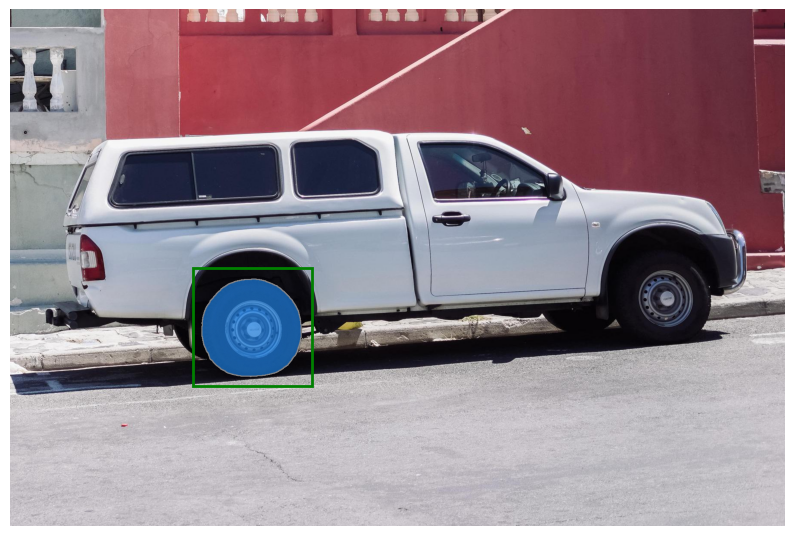

In [ ]:
show_masks(image, masks, scores, box_coords=input_box)

## Combining points and boxes

Points and boxes may be combined, just by including both types of prompts to the predictor. Here this can be used to select just the trucks's tire, instead of the entire wheel.

In [ ]:
input_box = np.array([425, 600, 700, 875])
input_point = np.array([[575, 750]])
input_label = np.array([0])

In [ ]:
masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    box=input_box,
    multimask_output=False,
)

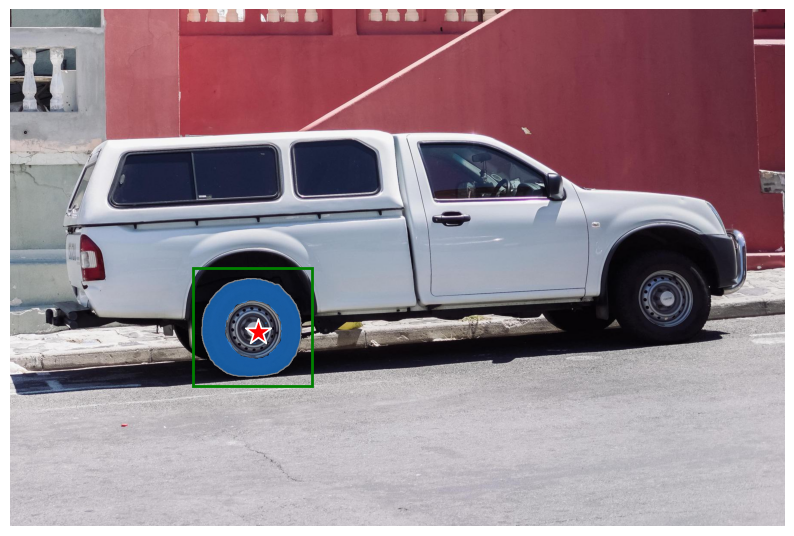

In [ ]:
show_masks(image, masks, scores, box_coords=input_box, point_coords=input_point, input_labels=input_label)

## Batched prompt inputs

`SAM2ImagePredictor` can take multiple input prompts for the same image, using `predict` method. For example, imagine we have several box outputs from an object detector.

In [ ]:
input_boxes = np.array([
    [75, 275, 1725, 850],
    [425, 600, 700, 875],
    [1375, 550, 1650, 800],
    [1240, 675, 1400, 750],
])

In [ ]:
masks, scores, _ = predictor.predict(
    point_coords=None,
    point_labels=None,
    box=input_boxes,
    multimask_output=False,
)

In [ ]:
masks.shape  # (batch_size) x (num_predicted_masks_per_input) x H x W

(4, 1, 1200, 1800)

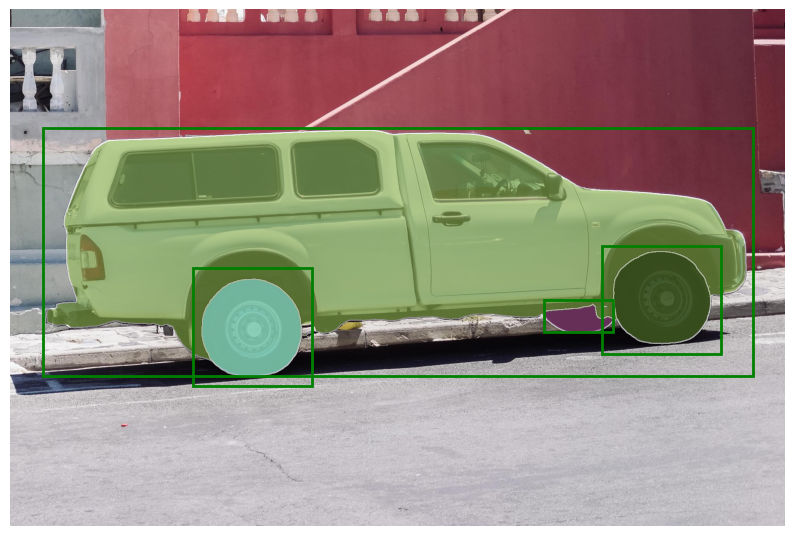

In [ ]:
plt.figure(figsize=(10, 10))
plt.imshow(image)
for mask in masks:
    show_mask(mask.squeeze(0), plt.gca(), random_color=True)
for box in input_boxes:
    show_box(box, plt.gca())
plt.axis('off')
plt.show()

## End-to-end batched inference
If all prompts are available in advance, it is possible to run SAM 2 directly in an end-to-end fashion. This also allows batching over images.

In [ ]:
image1 = image  # truck.jpg from above
image1_boxes = np.array([
    [75, 275, 1725, 850],
    [425, 600, 700, 875],
    [1375, 550, 1650, 800],
    [1240, 675, 1400, 750],
])

image2 = Image.open('images/groceries.jpg')
image2 = np.array(image2.convert("RGB"))
image2_boxes = np.array([
    [450, 170, 520, 350],
    [350, 190, 450, 350],
    [500, 170, 580, 350],
    [580, 170, 640, 350],
])

img_batch = [image1, image2]
boxes_batch = [image1_boxes, image2_boxes]

In [ ]:
predictor.set_image_batch(img_batch)

In [ ]:
masks_batch, scores_batch, _ = predictor.predict_batch(
    None,
    None,
    box_batch=boxes_batch,
    multimask_output=False
)

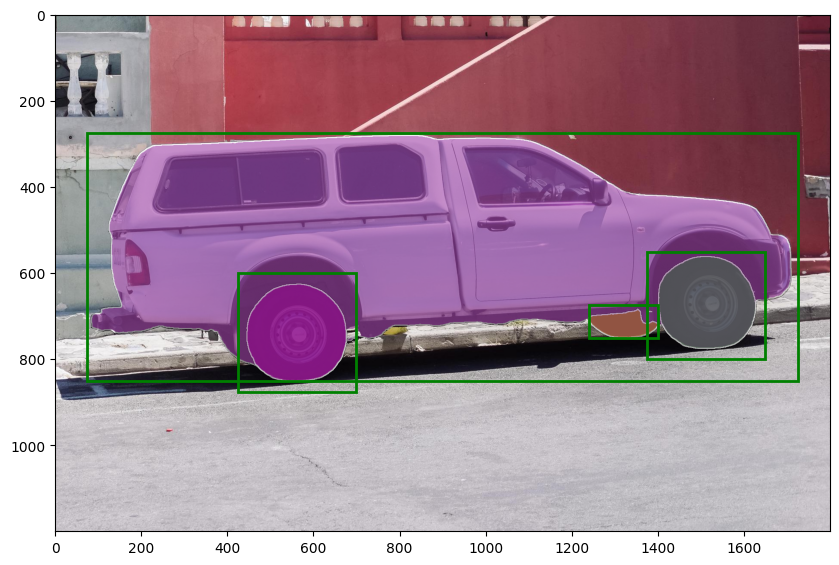

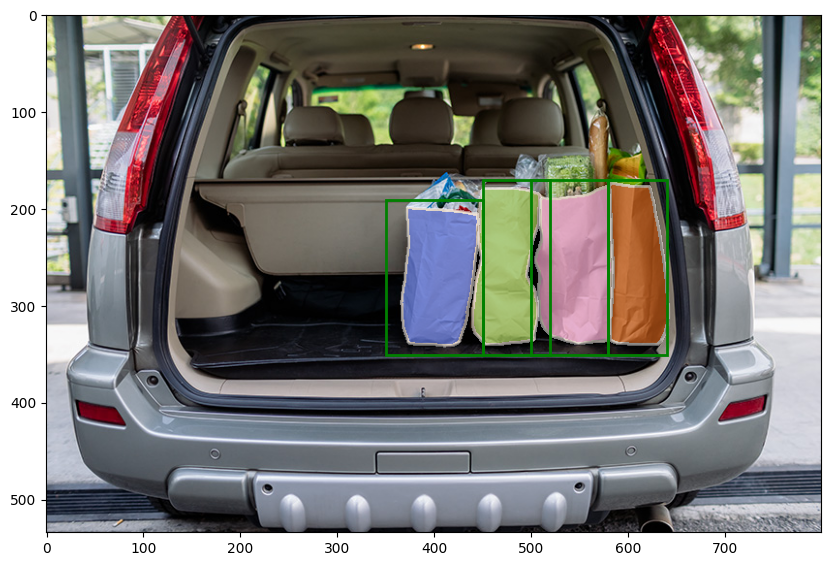

In [ ]:
for image, boxes, masks in zip(img_batch, boxes_batch, masks_batch):
    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    for mask in masks:
        show_mask(mask.squeeze(0), plt.gca(), random_color=True)
    for box in boxes:
        show_box(box, plt.gca())

Similarly, we can have a batch of point prompts defined over a batch of images

In [ ]:
image1 = image  # truck.jpg from above
image1_pts = np.array([
    [[500, 375]],
    [[650, 750]]
    ]) # Bx1x2 where B corresponds to number of objects
image1_labels = np.array([[1], [1]])

image2_pts = np.array([
    [[400, 300]],
    [[630, 300]],
])
image2_labels = np.array([[1], [1]])

pts_batch = [image1_pts, image2_pts]
labels_batch = [image1_labels, image2_labels]

In [ ]:
masks_batch, scores_batch, _ = predictor.predict_batch(pts_batch, labels_batch, box_batch=None, multimask_output=True)

# Select the best single mask per object
best_masks = []
for masks, scores in zip(masks_batch,scores_batch):
    best_masks.append(masks[range(len(masks)), np.argmax(scores, axis=-1)])

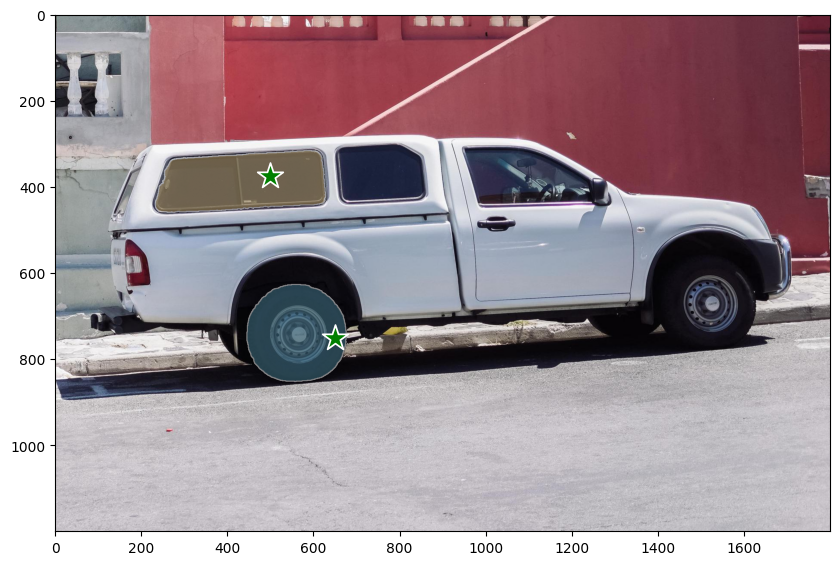

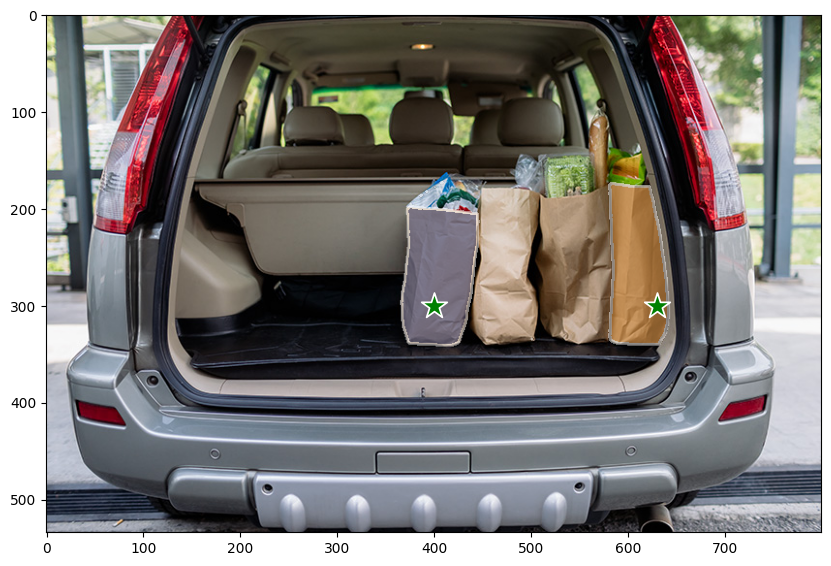

In [ ]:
for image, points, labels, masks in zip(img_batch, pts_batch, labels_batch, best_masks):
    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    for mask in masks:
        show_mask(mask, plt.gca(), random_color=True)
    show_points(points, labels, plt.gca())